In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, Conv1D, GlobalMaxPooling1D
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Dropout
from torch.utils.data import TensorDataset, DataLoader, random_split

In [2]:
df_r=pd.read_csv(r"C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\3DatasetsCombined.csv")
df_p=pd.read_csv(r"C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\combined_processed_v1.csv")

In [3]:


class BiLSTMModel(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, num_layers=2, num_classes=2):
        super(BiLSTMModel, self).__init__()

        # Embedding layer
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        # BiLSTM
        self.lstm = nn.LSTM(
            embed_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=0.3
        )

        # Dropout
        self.dropout = nn.Dropout(0.3)

        # Fully connected layers
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.embedding(x)              # (batch, seq, embed)

        lstm_out, _ = self.lstm(x)         # (batch, seq, hidden*2)

        # 🔥 Better than last timestep: use mean pooling
        x = torch.mean(lstm_out, dim=1)

        x = self.dropout(x)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        return self.fc2(x)

In [4]:
# ===== BiLSTM RAW =====

# data prep
from torch.cuda import device


df_r = df_r.dropna(subset=['text'])
df_r['text'] = df_r['text'].astype(str)
df_r = df_r.reset_index(drop=True)

texts_r = df_r['text']
labels_r = df_r['class'].values

# tokenizer
tokenizer_r = Tokenizer(num_words=10000)
tokenizer_r.fit_on_texts(texts_r)

X_r = pad_sequences(tokenizer_r.texts_to_sequences(texts_r), maxlen=100)
y_r = labels_r

# split
Xr_train, Xr_test, yr_train, yr_test, idxr_train, idxr_test = train_test_split(
    X_r, y_r, df_r.index,
    test_size=0.2,
    random_state=42,
    stratify=y_r
)

# tensors
Xr_train = torch.tensor(Xr_train, dtype=torch.long)
Xr_test  = torch.tensor(Xr_test, dtype=torch.long)
yr_train = torch.tensor(yr_train, dtype=torch.long)
yr_test  = torch.tensor(yr_test, dtype=torch.long)

# dataloader
train_loader_r = DataLoader(TensorDataset(Xr_train, yr_train), batch_size=32, shuffle=True)
test_loader_r  = DataLoader(TensorDataset(Xr_test, yr_test), batch_size=32)

# model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_r = BiLSTMModel(vocab_size=10000, num_classes=2).to(device)

criterion_r = nn.CrossEntropyLoss()
optimizer_r = optim.Adam(model_r.parameters(), lr=0.001)

# training
epochs = 2

for epoch in range(epochs):
    model_r.train()
    total_loss = 0

    for X_batch, y_batch in train_loader_r:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        outputs = model_r(X_batch)
        loss = criterion_r(outputs, y_batch)

        optimizer_r.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_r.parameters(), 1.0)
        optimizer_r.step()

        total_loss += loss.item()

    print(f"[RAW] Epoch {epoch+1} - Loss: {total_loss/len(train_loader_r):.4f}")

[RAW] Epoch 1 - Loss: 0.4212
[RAW] Epoch 2 - Loss: 0.3052


In [5]:
# ===== BiLSTM CLEAN =====

df_p = df_p.dropna(subset=['clean_text'])
df_p['clean_text'] = df_p['clean_text'].astype(str)
df_p = df_p.reset_index(drop=True)

texts_p = df_p['clean_text']
labels_p = df_p['class'].values

# tokenizer
tokenizer_p = Tokenizer(num_words=10000)
tokenizer_p.fit_on_texts(texts_p)

X_p = pad_sequences(tokenizer_p.texts_to_sequences(texts_p), maxlen=100)
y_p = labels_p

# split
Xp_train, Xp_test, yp_train, yp_test, idxp_train, idxp_test = train_test_split(
    X_p, y_p, df_p.index,
    test_size=0.2,
    random_state=42,
    stratify=y_p
)

# class weights ONLY here
from sklearn.utils.class_weight import compute_class_weight

classes_p = np.unique(yp_train)
weights_p = compute_class_weight('balanced', classes=classes_p, y=yp_train)
weights_p = torch.tensor(weights_p, dtype=torch.float).to(device)

# tensors
Xp_train = torch.tensor(Xp_train, dtype=torch.long)
Xp_test  = torch.tensor(Xp_test, dtype=torch.long)
yp_train = torch.tensor(yp_train, dtype=torch.long)
yp_test  = torch.tensor(yp_test, dtype=torch.long)

# dataloader
train_loader_p = DataLoader(TensorDataset(Xp_train, yp_train), batch_size=32, shuffle=True)
test_loader_p  = DataLoader(TensorDataset(Xp_test, yp_test), batch_size=32)

# model
model_p = BiLSTMModel(vocab_size=10000, num_classes=2).to(device)

criterion_p = nn.CrossEntropyLoss(weight=weights_p)
optimizer_p = optim.Adam(model_p.parameters(), lr=0.001)

# training
for epoch in range(epochs):
    model_p.train()
    total_loss = 0

    for X_batch, y_batch in train_loader_p:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        outputs = model_p(X_batch)
        loss = criterion_p(outputs, y_batch)

        optimizer_p.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_p.parameters(), 1.0)
        optimizer_p.step()

        total_loss += loss.item()

    print(f"[CLEAN] Epoch {epoch+1} - Loss: {total_loss/len(train_loader_p):.4f}")

[CLEAN] Epoch 1 - Loss: 0.4068
[CLEAN] Epoch 2 - Loss: 0.2872


In [6]:
model_r.eval()

preds_r = []
labels_r_eval = []

with torch.no_grad():
    for X_batch, y_batch in test_loader_r:
        X_batch = X_batch.to(device)

        outputs = model_r(X_batch)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()

        preds_r.extend(preds)
        labels_r_eval.extend(y_batch.numpy())

accuracy_r = accuracy_score(labels_r_eval, preds_r)
precision_r = precision_score(labels_r_eval, preds_r)
recall_r = recall_score(labels_r_eval, preds_r)
f1_r = f1_score(labels_r_eval, preds_r)

print("=== BiLSTM RAW ===")
print(f"Accuracy:  {accuracy_r:.4f}")
print(f"Precision: {precision_r:.4f}")
print(f"Recall:    {recall_r:.4f}")
print(f"F1 Score:  {f1_r:.4f}")

=== BiLSTM RAW ===
Accuracy:  0.8691
Precision: 0.9451
Recall:    0.8211
F1 Score:  0.8788


In [7]:
model_p.eval()

preds_p = []
labels_p_eval = []

with torch.no_grad():
    for X_batch, y_batch in test_loader_p:
        X_batch = X_batch.to(device)

        outputs = model_p(X_batch)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()

        preds_p.extend(preds)
        labels_p_eval.extend(y_batch.numpy())

accuracy_p = accuracy_score(labels_p_eval, preds_p)
precision_p = precision_score(labels_p_eval, preds_p)
recall_p = recall_score(labels_p_eval, preds_p)
f1_p = f1_score(labels_p_eval, preds_p)

print("\n=== BiLSTM CLEAN + WEIGHTS ===")
print(f"Accuracy:  {accuracy_p:.4f}")
print(f"Precision: {precision_p:.4f}")
print(f"Recall:    {recall_p:.4f}")
print(f"F1 Score:  {f1_p:.4f}")


=== BiLSTM CLEAN + WEIGHTS ===
Accuracy:  0.8695
Precision: 0.9389
Recall:    0.8280
F1 Score:  0.8800


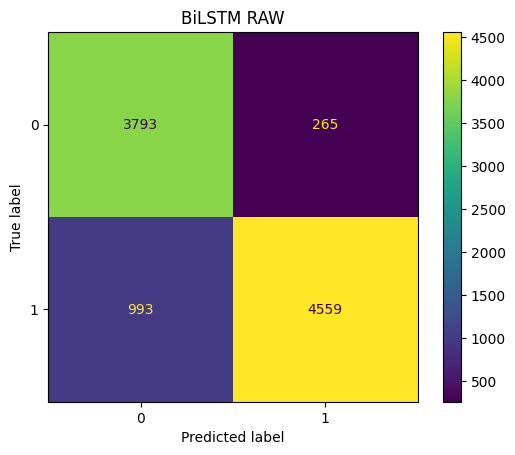

In [8]:
cm_r = confusion_matrix(labels_r_eval, preds_r)
ConfusionMatrixDisplay(cm_r).plot()
plt.title("BiLSTM RAW")
plt.show()

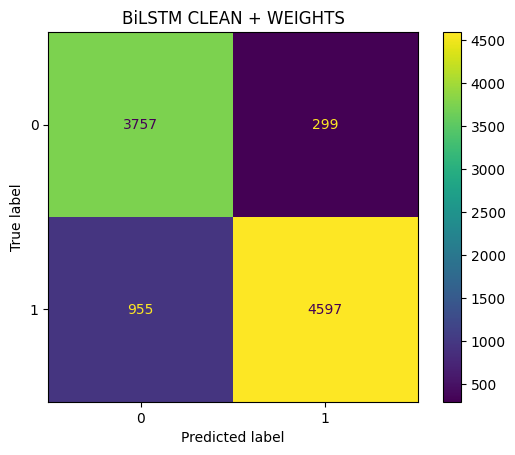

In [9]:
cm_p = confusion_matrix(labels_p_eval, preds_p)
ConfusionMatrixDisplay(cm_p).plot()
plt.title("BiLSTM CLEAN + WEIGHTS")
plt.show()

In [10]:
mis_r = np.where(np.array(preds_r) != np.array(labels_r_eval))[0]
wrong_idx_r = idxr_test[mis_r]

wrong_r = df_r.loc[wrong_idx_r].copy()
wrong_r['predicted'] = np.array(preds_r)[mis_r]

wrong_r[['text', 'class', 'predicted']].head(10)

,text,class,predicted
41591,""" momma said no pussy cats inside my doghouse """,0,1
11145,"RT @Racheldoesstuff: ""You gotta have luuuuube/...",1,0
786,"""CostaY, what shit u talking man ?""",0,1
45437,was a pedophile.,0,1
16326,"""Cadge me a fin.\xa0I'll pay you back.""",0,1
8568,Cute dumb females trash.,0,1
10676,"#MKR Kat and Andre get to stay, Seriously, Thi...",0,1
7459,"BAHAHAHA, OMG.. Kat has no idea.... NONE, , ...",1,0
40069,"""You are one sick puppy.""",1,0
11329,"""@Pickle\n\nYou look like Brian Scalabrine's b...",1,0


In [11]:
mis_p = np.where(np.array(preds_p) != np.array(labels_p_eval))[0]
wrong_idx_p = idxp_test[mis_p]

wrong_p = df_p.loc[wrong_idx_p].copy()
wrong_p['predicted'] = np.array(preds_p)[mis_p]

wrong_p[['clean_text', 'class', 'predicted']].head(10)

,clean_text,class,predicted
31517,ive went through 50 fag in 5 day not very happ...,1,0
43437,lookdumbfuck i am just pointing out the asshoi...,1,0
1743,a lot of money so u can sit on your as,0,1
40061,u coon cant wait to wear them oreo j,1,0
39434,rt my tbt i learn the english from that jabron...,1,0
35965,stop being a feminazi because you struggle at ...,1,0
37039,never ending horror of scum muslim oxfordabuse...,0,1
26746,eff it let go after the cripple,1,0
17540,rt suck yo momma flappy bird,1,0
30990,go back to your crapping unperfection home,1,0


In [12]:
#testing on real data samples
#Step 1: load datasets and get basic info
df_1=pd.read_csv(r'C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\labeled_data.csv')
df_2=pd.read_csv(r'C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\train_E6oV3lV.csv')

In [13]:
import re
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

lemmatizer = WordNetLemmatizer()

def full_preprocess(text):
    text = str(text).lower()
    
    # Step 2: remove URLs, mentions, keep hashtag words
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    
    # Step 3: normalize elongated words
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    
    # Step 4: remove punctuation + extra spaces
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    
    # Step 5: lemmatization
    tokens = word_tokenize(text)
    text = " ".join([lemmatizer.lemmatize(word) for word in tokens])
    
    return text

In [14]:

df_1 = df_1.rename(columns={'tweet': 'text'})
df_1['label'] = df_1['class'].apply(lambda x: 0 if x == 2 else 1)

# preprocessed
df_1['clean_text'] = df_1['text'].apply(full_preprocess)

In [15]:
df_2 = df_2.rename(columns={'tweet': 'text'})

# preprocessed
df_2['clean_text'] = df_2['text'].apply(full_preprocess)

In [16]:
# preprocessed
X1_clean = tokenizer_p.texts_to_sequences(df_1['clean_text'])
X1_clean = pad_sequences(X1_clean, maxlen=100)

# raw
X1_raw = tokenizer_r.texts_to_sequences(df_1['text'])
X1_raw = pad_sequences(X1_raw, maxlen=100)

In [17]:
# preprocessed
X2_clean = tokenizer_p.texts_to_sequences(df_2['clean_text'])
X2_clean = pad_sequences(X2_clean, maxlen=100)

# raw
X2_raw = tokenizer_r.texts_to_sequences(df_2['text'])
X2_raw = pad_sequences(X2_raw, maxlen=100)

In [18]:
X1_clean_t = torch.tensor(X1_clean, dtype=torch.long).to(device)
X1_raw_t   = torch.tensor(X1_raw, dtype=torch.long).to(device)

X2_clean_t = torch.tensor(X2_clean, dtype=torch.long).to(device)
X2_raw_t   = torch.tensor(X2_raw, dtype=torch.long).to(device)

In [19]:
y1 = df_1['label'].values
y2 = df_2['label'].values

In [20]:
def evaluate_preds(y_true, preds, title=""):
    print(title)
    print("Accuracy:", accuracy_score(y_true, preds))
    print("Precision:", precision_score(y_true, preds))
    print("Recall:", recall_score(y_true, preds))
    print("F1:", f1_score(y_true, preds))
    print("-" * 40)

In [21]:
def predict_r(model_r, X_tensor):
    model_r.eval()
    with torch.no_grad():
        outputs = model_r(X_tensor)
        return torch.argmax(outputs, dim=1).cpu().numpy()

In [22]:
def predict_p(model_p, X_tensor):
    model_p.eval()
    with torch.no_grad():
        outputs = model_p(X_tensor)
        return torch.argmax(outputs, dim=1).cpu().numpy()

In [23]:
# df1 - Davidson - all 4 combinations
preds_r_r = predict_r(model_r, X1_raw_t)
preds_r_c = predict_r(model_r, X1_clean_t)
preds_p_r = predict_p(model_p, X1_raw_t)
preds_p_c = predict_p(model_p, X1_clean_t)

evaluate_preds(y1, preds_r_r, "BiLSTM - DF1 | Raw Model - Raw Input")
evaluate_preds(y1, preds_r_c, "BiLSTM - DF1 | Raw Model - Clean Input")
evaluate_preds(y1, preds_p_r, "BiLSTM - DF1 | Clean Model - Raw Input")
evaluate_preds(y1, preds_p_c, "BiLSTM - DF1 | Clean Model - Clean Input")

BiLSTM - DF1 | Raw Model - Raw Input
Accuracy: 0.946374530928459
Precision: 0.9888500329430845
Recall: 0.9462172647914646
F1: 0.9670640132834378
----------------------------------------
BiLSTM - DF1 | Raw Model - Clean Input
Accuracy: 0.4476052132510188
Precision: 0.8690095846645367
Recall: 0.3957322987390883
F1: 0.5438187270909697
----------------------------------------
BiLSTM - DF1 | Clean Model - Raw Input
Accuracy: 0.40257434531735464
Precision: 0.8295918367346938
Recall: 0.3548496605237633
F1: 0.4970788043478261
----------------------------------------
BiLSTM - DF1 | Clean Model - Clean Input
Accuracy: 0.9450026227656054
Precision: 0.987494304085869
Recall: 0.9458777885548012
F1: 0.966238141239999
----------------------------------------


In [24]:
# df2 - TSA - all 4 combinations
preds_r_r = predict_r(model_r, X2_raw_t)
preds_r_c = predict_r(model_r, X2_clean_t)
preds_p_r = predict_p(model_p, X2_raw_t)
preds_p_c = predict_p(model_p, X2_clean_t)

evaluate_preds(y2, preds_r_r, "BiLSTM - DF2 | Raw Model - Raw Input")
evaluate_preds(y2, preds_r_c, "BiLSTM - DF2 | Raw Model - Clean Input")
evaluate_preds(y2, preds_p_r, "BiLSTM - DF2 | Clean Model - Raw Input")
evaluate_preds(y2, preds_p_c, "BiLSTM - DF2 | Clean Model - Clean Input")

BiLSTM - DF2 | Raw Model - Raw Input
Accuracy: 0.9072023027344972
Precision: 0.18630849220103987
Recall: 0.09589652096342552
F1: 0.12661955241460543
----------------------------------------
BiLSTM - DF2 | Raw Model - Clean Input
Accuracy: 0.7380326637882485
Precision: 0.09022857906696966
Recall: 0.3010704727921499
F1: 0.13884603517432892
----------------------------------------
BiLSTM - DF2 | Clean Model - Raw Input
Accuracy: 0.6300606970777799
Precision: 0.07443595665304673
Recall: 0.37377341659232827
F1: 0.12414814814814815
----------------------------------------
BiLSTM - DF2 | Clean Model - Clean Input
Accuracy: 0.9056066579062637
Precision: 0.25428027901078
Recall: 0.17885816235504015
F1: 0.2100026184865148
----------------------------------------
